# CSE558 End-term, group DSC 10: coresets for 42-day hub demand, and the frozen forecaster

This notebook rebuilds every number, table and figure of `report/main.pdf` from the files in this folder. It fits no model:
the heavy runs (37 origin tables, 260 end-term fits, TabPFN-TS on a GPU, the final retrain) were done on a server and their
outputs are saved in `results/`, `artifacts/` and `final/`. Running it top to bottom takes well under a minute on a laptop.

**Sections**
1. Data, split and metric
2. Full model $x^*$ and ridge
3. Plot 1: rows (uniform, hub-stratified, sensitivity coreset) and columns
4. Plot 2 and the speed-up table
5. Coreset: $S$, $\alpha$, Plots 3-5 and slopes
6. Improving $x^*$: search results and the experiment ledger
7. Freeze audit: the gate recomputed from saved out-of-fold predictions
8. The frozen artifact: hashes and hard checks

In [1]:
import json, sys, hashlib
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
sys.path.insert(0, str(ROOT / 'code'))
RES, FIG, ART, FIN = ROOT/'results', ROOT/'figures', ROOT/'artifacts', ROOT/'final'
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
print(sys.version.split()[0], 'pandas', pd.__version__, 'numpy', np.__version__)

3.11.13 pandas 2.3.3 numpy 2.4.6


## 1. Data, split and metric
One row = (forecast origin, hub, target day). 1,115 hubs, 42-day horizon, 342 feature columns built from history up to the
origin only. End-term split: train = origins whose label window ends by 2015-05-08; test = 2015-05-09 .. 2015-06-19
(46,830 rows). Metric: RMSLE = RMSE of `log1p`; $R^2$ on the log scale; closed days kept in test with prediction 0.

**Why log1p:** volumes are right-skewed and errors should be relative (a miss of 500 orders matters more at a small hub).
**Why keep closed days:** the forecast file must cover them; they are predicted as exactly 0, so their error is 0, which
inflates $R^2$. We therefore also report RMSLE without open-but-zero rows.

In [2]:
raw = ROOT.parent / '1_midterm' / 'data' / 'raw'
train = pd.read_csv(raw / 'orders_train.csv', usecols=['HubID', 'Date'])
test = pd.read_csv(raw / 'orders_test.csv')
print('raw training rows', len(train), 'hubs', train.HubID.nunique(), 'dates', train.Date.min(), '..', train.Date.max())
print('forecast frame rows', len(test), 'closed rows', int((test.IsOpen == 0).sum()))
print('end-term training cells: 1,133,640 rows x 342 columns =', f'{1_133_640*342:,}')

raw training rows 970379 hubs 1115 dates 2013-01-01 .. 2015-06-19
forecast frame rows 46830 closed rows 6548
end-term training cells: 1,133,640 rows x 342 columns = 387,704,880


## 2. Full model $x^*$ (LightGBM) and the second model (ridge)

In [3]:
et = pd.read_csv(RES / 'endterm_run1_results.csv')
et[et.method == 'full'][['model', 'test_rmsle', 'test_rmsle_excl_open0', 'test_r2', 't_train']].round(4)

,model,test_rmsle,test_rmsle_excl_open0,test_r2,t_train
0,lgbm,0.1022,0.0932,0.9992,59.6865
106,ridge,0.1592,0.1539,0.9980,4.3233


LightGBM is 36% lower in RMSLE than ridge: demand depends on interactions (weekday x promotion x format, holidays,
data gaps) that trees capture directly. Ridge is kept because coreset theory is exact for it, so it checks the method.

## 3. Plot 1: test RMSLE against summary size (median of 5 repeats)

method            hub_stratified  importance  sensitivity  uniform  coreset_minus_uniform
model     m                                                                              
lgbm      2000            0.1322         NaN       0.1318   0.1297                 0.0021
          5000            0.1221         NaN       0.1195   0.1218                -0.0024
          10000           0.1203         NaN       0.1170   0.1187                -0.0017
          25000           0.1131         NaN       0.1108   0.1133                -0.0024
          50000           0.1117         NaN       0.1070   0.1102                -0.0032
          100000          0.1087         NaN       0.1058   0.1099                -0.0041
          200000          0.1054         NaN       0.1045   0.1055                -0.0010
lgbm_cols 10                 NaN      0.1324          NaN   0.2316                    NaN
          20                 NaN      0.1204          NaN   0.1658                    NaN
          40                 NaN      0.1102          NaN   0.1770                    NaN
          80                 NaN      0.1087          NaN   0.1248                    NaN
          160                NaN      0.1058          NaN   0.1129                    NaN
ridge     2000            0.1634         NaN       0.1608   0.1663                -0.0055
          5000            0.1602         NaN       0.1611   0.1615                -0.0003
          10000           0.1628         NaN       0.1607   0.1613                -0.0006
          25000           0.1607         NaN       0.1611   0.1620                -0.0009
          50000           0.1593         NaN       0.1592   0.1605                -0.0013
          100000          0.1585         NaN       0.1595   0.1595                -0.0000
          200000          0.1592         NaN       0.1599   0.1593                 0.0006

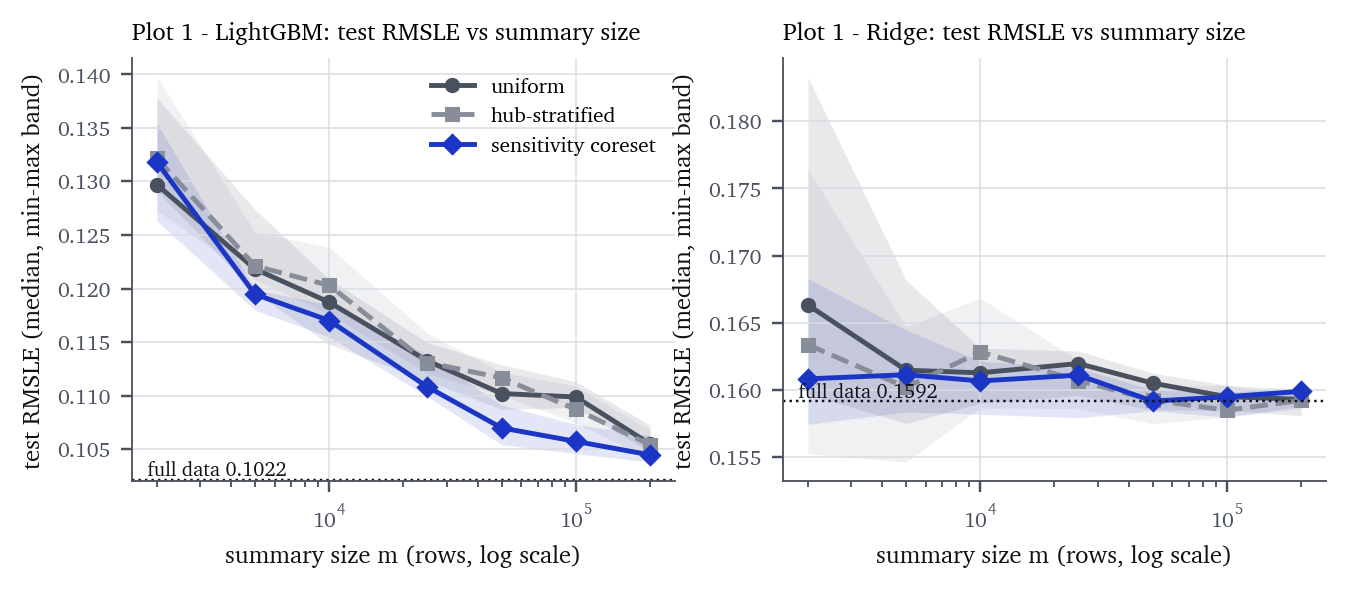

In [4]:
rows = et[et.method != 'full'].pivot_table(index=['model', 'm'], columns='method', values='test_rmsle', aggfunc='median')
rows['coreset_minus_uniform'] = rows['sensitivity'] - rows['uniform']
display(rows.round(4))
display(Image(FIG / 'fig_plot1_rows.png'))

**Reading.** For LightGBM the coreset beats uniform from 5k to 200k rows (by 0.0032 at 50k) and ties at 2k, where a tree
with min child 80 cannot use the weight variance. Hub-stratified is no better than uniform. For ridge all methods agree:
a 5k-row ridge is already within 0.003 of the full fit.

**Columns** (rows fixed at 200k): importance-chosen vs random columns. Trees need original columns, so no random projection.

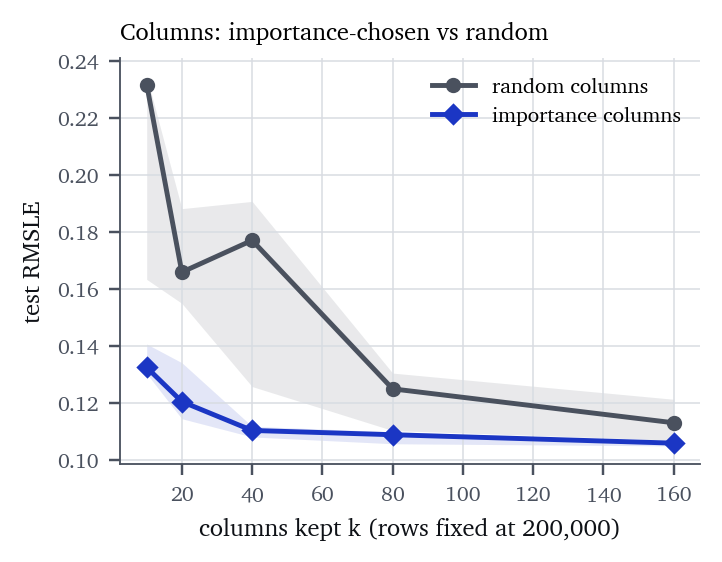

In [5]:
display(Image(FIG / 'fig_plot1_columns.png'))

## 4. Plot 2: time, and the speed-up table

,model,method,m,test_rmsle,delta_vs_full,t_build,t_train,speedup
0,lgbm,uniform,2000,0.1297,0.0275,0.0002,1.7364,34.3692
1,lgbm,uniform,5000,0.1218,0.0197,0.0005,4.5153,13.2171
2,lgbm,uniform,10000,0.1187,0.0166,0.0010,7.3749,8.0920
3,lgbm,uniform,25000,0.1133,0.0111,0.0032,9.4996,6.2815
4,lgbm,uniform,50000,0.1102,0.0081,0.0052,11.5095,5.1835
5,lgbm,uniform,100000,0.1099,0.0077,0.0100,13.5741,4.3938
6,lgbm,uniform,200000,0.1055,0.0034,0.0200,36.5474,1.6323
7,lgbm,hub_stratified,2000,0.1322,0.0300,0.6649,1.7133,25.0969
8,lgbm,hub_stratified,5000,0.1221,0.0200,0.6609,4.0315,12.7199
9,lgbm,hub_stratified,10000,0.1203,0.0181,0.6724,7.5642,7.2583


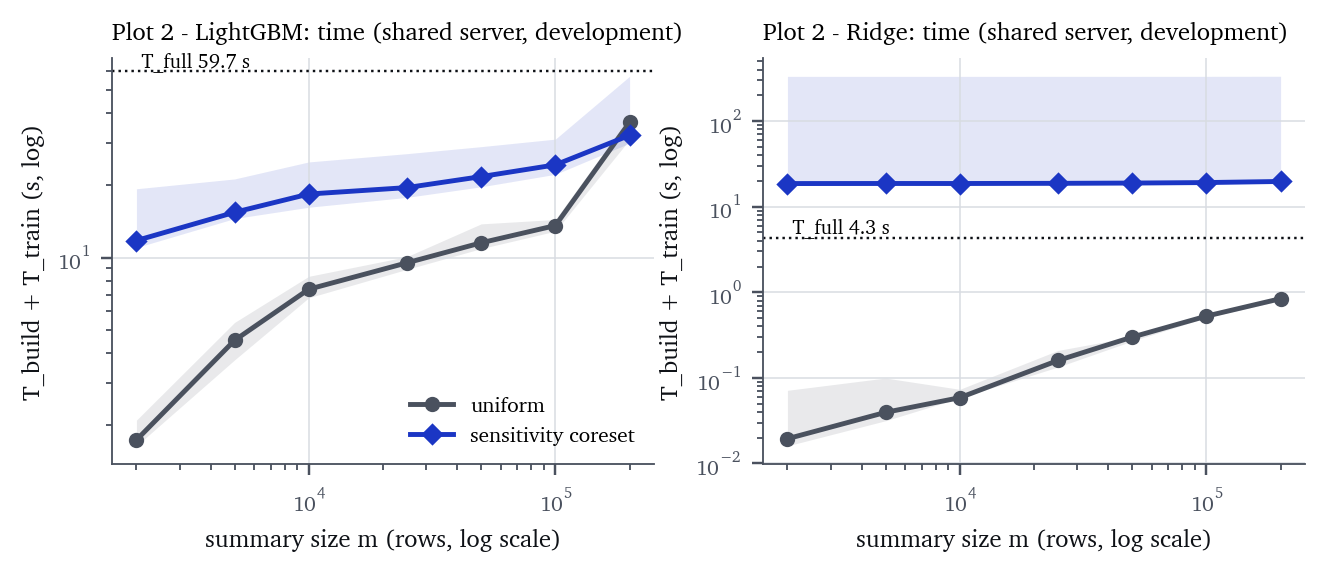

In [6]:
sp = pd.read_csv(RES / 'endterm_run1_speedup.csv')
display(sp[sp.model == 'lgbm'].round(4))
display(Image(FIG / 'fig_plot2_time.png'))

Uniform is always faster (no build); the coreset is always more accurate from 5k rows. At the chosen size, 50k rows:
coreset 0.1070 at 2.75x, uniform 0.1102 at 5.18x, full 0.1022. **Limitation:** timings come from a shared server
(load 10-30); an exclusive rerun is still open.

## 5. Coreset: total sensitivity, roughness, Plots 3-5

lgbm: log-log slope of Plot 3 coreset -0.59, uniform -0.48; Plot 5 coreset -0.19, uniform -0.18; ratio Plot5/Plot3 (coreset) 0.33
ridge: log-log slope of Plot 3 coreset -0.78, uniform -0.99; Plot 5 coreset -0.52, uniform -0.50; ratio Plot5/Plot3 (coreset) 0.66
              S  alpha_max
model                     
lgbm   2.466848   2.445402
ridge  2.120734   1.012389


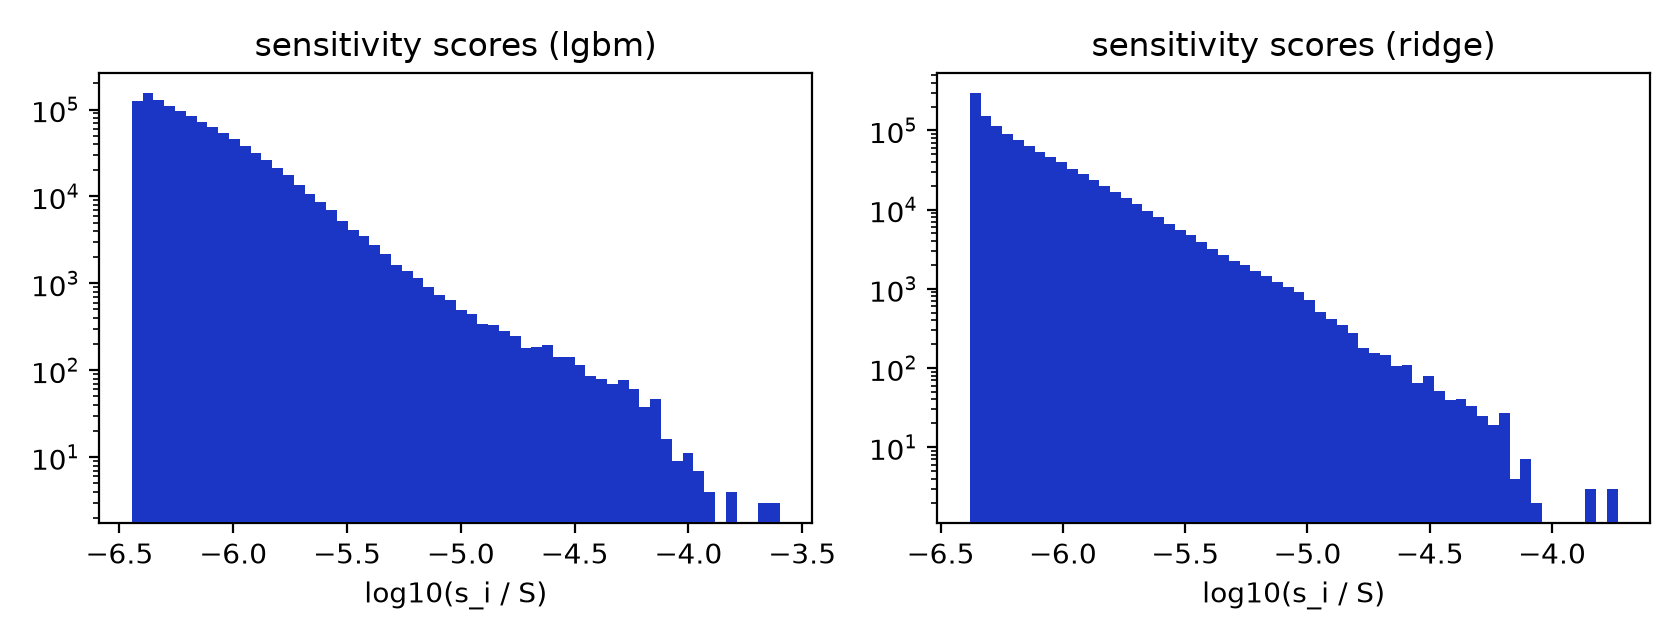

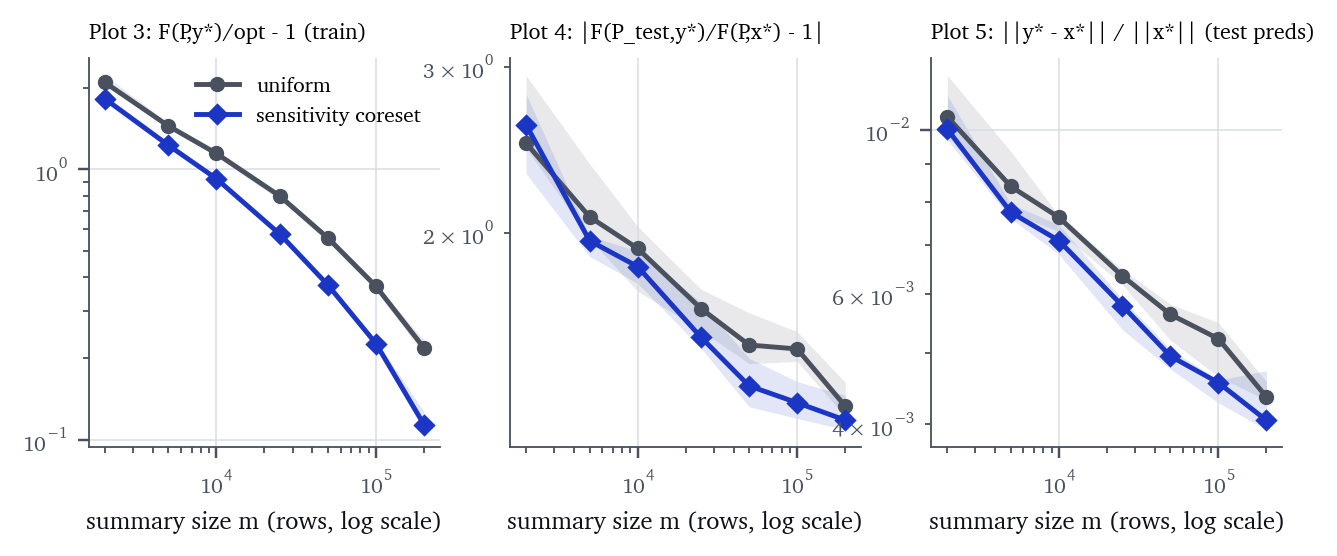

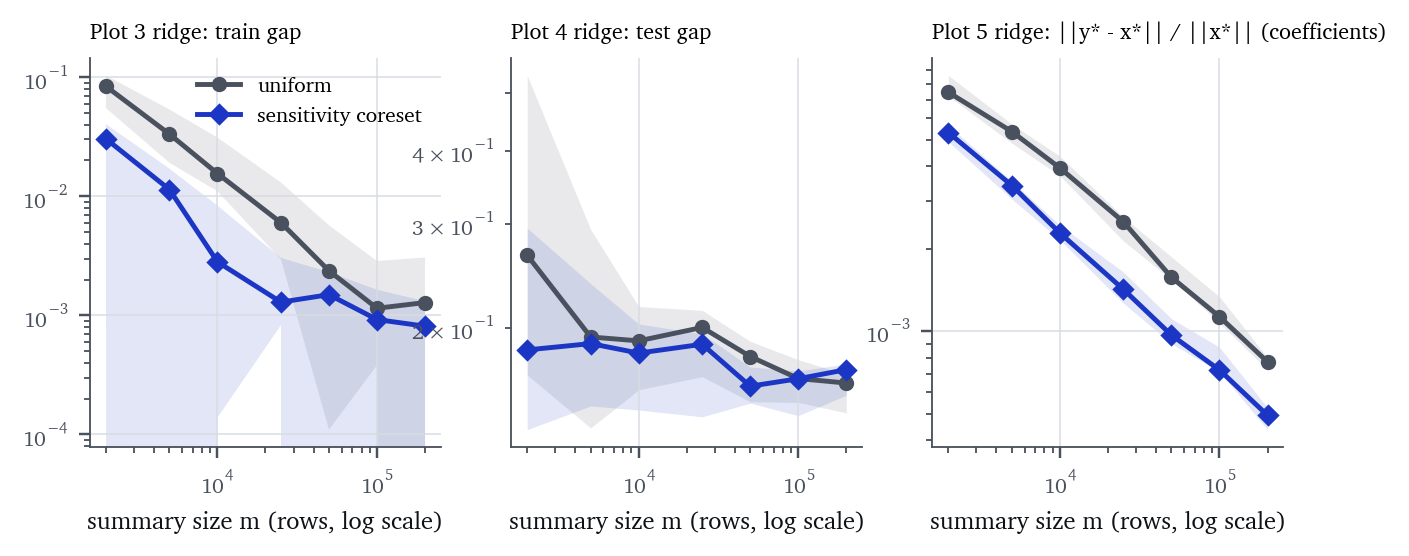

In [7]:
print(open(RES / 'endterm_run1_slopes_and_S.txt').read())
display(Image(FIG / 'fig_hist_sensitivity.png'))
display(Image(FIG / 'fig_plot345_lgbm.png'))
display(Image(FIG / 'fig_plot345_ridge.png'))

$S$ must lie in $[2,6]$ for five rough models and one group (the denominator is the weighted **sum** of losses, so each
rough model contributes exactly 1). Measured 2.47 and 2.12. For ridge the coefficient error (Plot 5) falls at 0.66 times the rate
of the loss gap (theory: about 0.5). For trees the ratio is 0.33 and there is no guarantee; we call the method heuristic
sensitivity-motivated importance sampling.

## 6. Improving $x^*$: what the searches found

Gate (fixed before the runs): mean gain over folds 2-4 >= 0.0024 (twice the noise 0.0012), >= 2 of 3 folds improve, same sign on
seeds 20260807/08/09, still true without open-but-zero rows, fold 5 checked.

,v,cs,leaves,mcs,lam,ext,f1,f2,f3,f4,mean,x_mean,it,g_f1,g_f2,g_f3,g_f4,g_mean,g234,n234
0,hp_017,0.15,255,160,24.10,0,0.128794,0.120240,0.107786,0.102685,0.114876,0.109048,873,0.009029,0.001220,0.005092,0.001223,0.004141,0.002512,1
1,hp_006,0.10,63,320,22.67,0,0.131831,0.118318,0.115133,0.104123,0.117351,0.111557,1479,0.005991,0.003142,-0.002255,-0.000215,0.001666,0.000224,1
2,hp_014,0.15,255,160,2.86,1,0.131024,0.119639,0.114849,0.104321,0.117459,0.111744,738,0.006798,0.001821,-0.001971,-0.000414,0.001559,-0.000188,0
3,hp_008,0.10,255,40,0.71,0,0.134971,0.118081,0.113340,0.104653,0.117761,0.112024,663,0.002851,0.003379,-0.000462,-0.000746,0.001256,0.000724,1
4,hp_012,0.30,255,80,1.63,0,0.132279,0.119756,0.115421,0.104228,0.117921,0.112091,826,0.005544,0.001704,-0.002542,-0.000321,0.001096,-0.000386,0
5,hp_007,0.20,63,80,9.98,0,0.138601,0.121049,0.110257,0.102349,0.118064,0.112370,1474,-0.000779,0.000411,0.002622,0.001558,0.000953,0.001530,1
6,hp_011,0.30,255,40,2.74,0,0.133847,0.119679,0.114030,0.105519,0.118269,0.112523,370,0.003975,0.001781,-0.001152,-0.001611,0.000748,-0.000328,0
7,hp_003,0.30,255,40,7.39,0,0.134554,0.120789,0.113443,0.104886,0.118418,0.112653,372,0.003268,0.000671,-0.000564,-0.000978,0.000599,-0.000290,0
8,hp_000,0.20,63,80,1.00,0,0.137822,0.121460,0.112878,0.103908,0.119017,0.113350,1151,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0
9,hp_010,0.40,255,80,1.21,0,0.134041,0.119853,0.118023,0.104511,0.119107,0.113389,1047,0.003781,0.001607,-0.005144,-0.000604,-0.000090,-0.001380,0


Optuna trials 80  best 0.1105  top-10 span 0.0005


,study,trial,feature_fraction,num_leaves,min_data_in_leaf,lambda_l2,objective
0,g6c_blend,21,0.1688,255,123,1.8756,0.1105
1,g6c_blend,35,0.1678,255,220,2.0902,0.1105
2,g6c_blend_b,30,0.1940,383,133,14.7352,0.1106
3,g6c_blend_b,28,0.1951,383,124,14.2027,0.1107
4,g6c_blend,37,0.1736,383,140,5.2006,0.1108
5,g6c_blend_b,24,0.2051,383,174,15.8737,0.1109
6,g6c_blend_b,25,0.1956,383,185,14.0374,0.1109
7,g6c_blend,1,0.1500,255,160,24.1000,0.1109


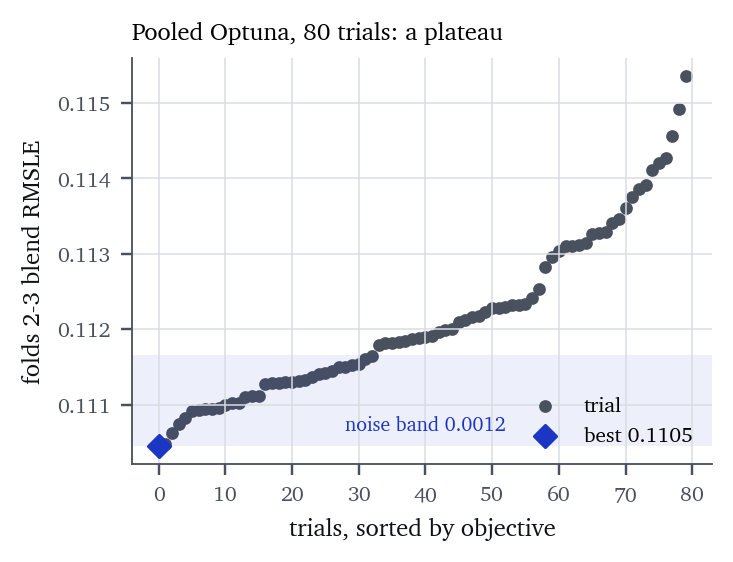

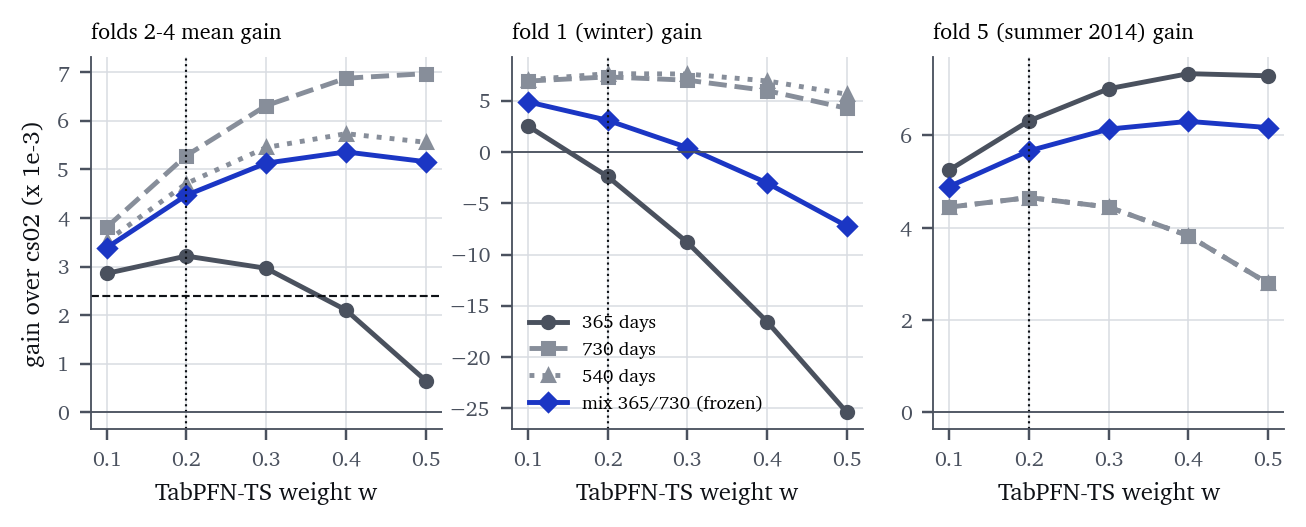

In [8]:
hp = pd.read_csv(RES / 'hp_search_20configs.csv')
display(hp.head(25))
op = pd.read_csv(RES / 'g6c_pooled_80_trials.csv').sort_values('objective')
print('Optuna trials', len(op), ' best', round(op.objective.iloc[0], 4), ' top-10 span', round(op.objective.iloc[9] - op.objective.iloc[0], 4))
display(op[['study', 'trial', 'feature_fraction', 'num_leaves', 'min_data_in_leaf', 'lambda_l2', 'objective']].head(8).round(4))
display(Image(FIG / 'fig_optuna.png'))
display(Image(FIG / 'fig_tabpfn_grid.png'))

The full experiment ledger, negatives included, with the reason each idea failed:

In [9]:
print(open(RES / 'experiment_ledger.md').read())

# Experiment ledger: every idea tried on the forecaster, with the measured result and the reason

All numbers are RMSLE on our own time-ordered development folds (fold 1 = 2015-01-02, fold 2 = 2015-02-13, fold 3 = 2015-03-27,
fold 4 = 2015-05-08, 46,830 rows each; fold 5 = 2014-06-19, season-matched to the forecast window). "Gain" = baseline minus
candidate (positive = better). Gate: mean gain over folds 2-4 >= 0.0024 (2 x measured noise 0.0012), >= 2 of 3 folds improve,
same sign on seeds 20260807/08/09, holds without open-but-zero rows, fold 5 checked. A "challenger" is better on most folds but
misses the gate; it is not adopted.

## A. Baselines and the path to the frozen model

| Step | RMSLE (mean folds 1-4) | Note |
|---|---|---|
| Earlier 3-model blend (CatBoost + LightGBM + Tweedie), re-scored on corrected folds | 0.1250 | corrected folds: no early stopping on the evaluated fold, cross-fitted hub encoding |
| LightGBM `base` (feature fraction 0.8, no bagging) | 0.1312 | single 

## 7. Freeze audit: the gate recomputed from saved out-of-fold predictions
`code/freeze_audit.py` reads the out-of-fold files of the baseline (`cs02`, lr 0.025, 1000 fixed rounds, 3 seeds), `hp17` (same
setting, 3 seeds) and TabPFN-TS (365- and 730-day contexts), rebuilds the blend and recomputes every gate number.

,arm,candidate,gain_f1,gain_f2,gain_f3,gain_f4,gain_f5,mean_gain_f2_4,folds_improved_2_4,mean_gain_f2_4_excl0,gain_f5_excl0
0,seed07,hp17,0.0047,0.0013,0.0032,0.0015,0.0014,0.0020,3,0.0021,0.0022
1,seed07,candidate,0.0024,0.0055,0.0044,0.0043,0.0035,0.0047,3,0.0049,0.0055
2,seed07,fallback_hp17_t365,-0.0032,0.0046,0.0024,0.0035,0.0042,0.0035,3,0.0036,0.0065
3,seed08,hp17,0.0063,-0.0003,0.0051,0.0006,0.0054,0.0018,2,0.0019,0.0084
4,seed08,candidate,0.0038,0.0043,0.0062,0.0034,0.0075,0.0047,3,0.0049,0.0118
5,seed08,fallback_hp17_t365,-0.0016,0.0035,0.0042,0.0027,0.0083,0.0034,3,0.0036,0.0128
6,seed09,hp17,0.0059,0.0002,0.0051,-0.0002,0.0047,0.0017,2,0.0017,0.0073
7,seed09,candidate,0.0039,0.0040,0.0065,0.0032,0.0067,0.0046,3,0.0047,0.0105
8,seed09,fallback_hp17_t365,-0.0014,0.0029,0.0046,0.0024,0.0071,0.0033,3,0.0034,0.0110
9,3seed,hp17,0.0058,0.0005,0.0045,0.0007,0.0038,0.0019,3,0.0019,0.0060


hp17 FAILS {'mean_gain_f2_4_3seed_ge_0.0024': False, 'every_seed_mean_gain_f2_4_ge_0.0024': False, 'at_least_2_of_3_folds_improve_every_seed': True, 'same_sign_all_seeds': True, 'holds_excl_open_zero': False, 'fold5_positive_every_seed': True}
candidate PASSES {'mean_gain_f2_4_3seed_ge_0.0024': True, 'every_seed_mean_gain_f2_4_ge_0.0024': True, 'at_least_2_of_3_folds_improve_every_seed': True, 'same_sign_all_seeds': True, 'holds_excl_open_zero': True, 'fold5_positive_every_seed': True}
fallback_hp17_t365 PASSES {'mean_gain_f2_4_3seed_ge_0.0024': True, 'every_seed_mean_gain_f2_4_ge_0.0024': True, 'at_least_2_of_3_folds_improve_every_seed': True, 'same_sign_all_seeds': True, 'holds_excl_open_zero': True, 'fold5_positive_every_seed': True}


,fold,rows,cs02_all,hp17_all,candidate_all,candidate_excl0
15,1,46830,0.1333,0.1275,0.1302,0.1231
16,2,46830,0.1186,0.1180,0.1141,0.1065
17,3,46830,0.1127,0.1083,0.1073,0.1073
18,4,46830,0.1033,0.1026,0.0999,0.0909
19,5,39270,0.1794,0.1756,0.1737,0.1105


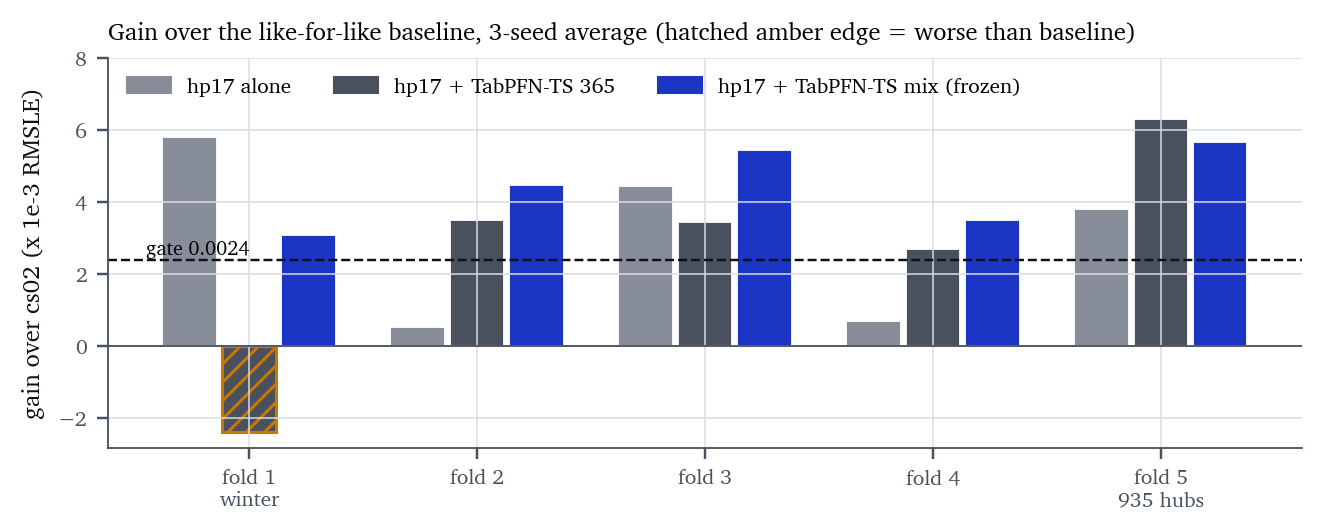

In [10]:
import freeze_audit as fa
panel, full_rows = fa.build_panel()
folds, gains = fa.gate_tables(panel)
display(gains.round(4))
for c in ('hp17', 'candidate', 'fallback_hp17_t365'):
    v = fa.gate_verdict(gains, c); print(c, 'PASSES' if v['passes'] else 'FAILS', v['checks'])
display(folds[folds.arm == '3seed'][['fold', 'rows', 'cs02_all', 'hp17_all', 'candidate_all', 'candidate_excl0']].round(4))
display(Image(FIG / 'fig_gate_gains.png'))

In [11]:
mix = fa.context_mix_check(panel)
print(json.dumps(mix, indent=1))

{
 "oof_rows_compared": 187320,
 "oof_max_abs_log_diff": 0.0,
 "oof_folds": [
  1,
  2,
  3,
  4
 ],
 "oof730_rebuilt_from_split_files_max_abs_diff": 0.0,
 "test_ids_equal_across_files": true,
 "test_mix_max_abs_log_diff": 0.0,
 "test_mix_sha256": "6d5eb125bbad218e89667be9c0fdeae5192ed9ca8e3324c9127f8a15b697cab3",
 "test365_sha256": "3c2f6c403b7efaf5ee72fc9c6f6129ab00fdc2f24ee90fb02de944faa3e8058e",
 "test730_sha256": "460f22250c2d65812051c3c0045e95141fb7540712e6b9787288bf0ecfb9e4e7",
 "test365_vs_730_corr_log": 0.9996913618164334,
 "test365_sha_matches_its_manifest": true,
 "test730_sha_matches_its_manifest": true,
 "history_last_date": [
  "2015-06-19",
  "2015-06-19"
 ],
 "forecast_origin": [
  "2015-06-19",
  "2015-06-19"
 ],
 "contexts": [
  365,
  730
 ]
}


## 8. The frozen artifact

In [12]:
man = json.loads((FIN / 'final_manifest.json').read_text())
run = man['_run']
print('recipe', run['recipe'], run['config']['variant'], '| blend weight', run['blend_weight'], run['blend']['external']['space'])
print('training origins', run['training_origins'], '| last label', run['last_label_date'], '| forecast origin', run['forecast_origin'])
print('versions', run['versions'])
for k, v in man.items():
    if k.startswith('lightgbm_'): print(k, v['sha256'])
print('forecast file sha256', run['submission_sha256'])
print(json.dumps(json.loads((FIN / 'freeze_checks.json').read_text()), indent=1))

recipe hp17 hp17_fix1000 | blend weight 0.2 log1p
training origins 37 | last label 2015-06-19 | forecast origin 2015-06-19
versions {'python': '3.11.18', 'lightgbm': '4.7.0', 'numpy': '1.25.2', 'pandas': '2.3.3', 'scikit-learn': '1.7.2'}
lightgbm_s20260807 613aa09dedaa65b796dcc39cee89374b1ceee96fb4e3ebc005b2f31c33b1a816
lightgbm_s20260808 d0a4af424ff9f300c9aab70a92ce557ad57e136f6296aed8051ecc662412dc4a
lightgbm_s20260809 fa798ad0c64b95eb3556361cdf37630d2a5011c96b1040b061636d66e50c6ba7
forecast file sha256 7d44a05089c6174d20afb07fb6a72414b540794f6ca86e2ae94ed483c0fc4484
{
 "submission_sha256": "7d44a05089c6174d20afb07fb6a72414b540794f6ca86e2ae94ed483c0fc4484",
 "submission_sha_matches_manifest": true,
 "blend_file_sha_matches_manifest": true,
 "rows": 46830,
 "rows_ok": true,
 "id_order_equals_sample_submission": true,
 "id_order_equals_test_frame": true,
 "any_nan_or_inf": false,
 "any_negative": false,
 "closed_rows": 6548,
 "closed_rows_exact_zero": true,
 "open_rows_predicted_zero":

**Limits kept with the result:** `hp17` was the best of 19 configs and its gain shrank on fresh seeds; the context mix was
defined after seeing 365 and 730; the weight 0.2 sits in a flat curve chosen on folds 2-4 (including fold 4); folds 1, 4 and 5 are
diagnostics, not untouched test sets; the real forecast window has no labels in this project, so no real test score exists.